# Laboratory Exercise 1: Job Postings

Open Jobs is a job board that lists open positions from employers and recruitment agencies across Macedonia. Its pages are a stored snapshot in `data/site`, and the setup serves them from this machine together with the statistics service of the board, so every request stays on the local loopback address. The postings are synthetic and describe no real employer, agency, or person.

Answer each request in the cells below it, and add as many cells as you need. The laboratory test asks for values and decisions that your notebook computes, so keep every result visible, run the notebook from top to bottom before you submit it, and make sure it runs on a machine without internet access.

## Setup

The cells in this section are written already. Run them before the tasks.

In [1]:
import json
import re
import threading
from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urljoin, urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup, Tag
from playwright.async_api import async_playwright
from scipy import stats
from statsmodels.stats.multitest import multipletests

DATA = Path("data")
# Every random step draws from this generator, so a rerun gives the same result.
rng = np.random.default_rng(2026)

In [2]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [3]:
# The statistics service answers /api/posting-stats?page=N from a stored file,
# and every other path is a file under the site directory.
STATS = json.loads((DATA / "api" / "posting-stats.json").read_text(encoding="utf-8"))
STATS_PER_PAGE = 50


class Board(SimpleHTTPRequestHandler):
    extensions_map = {
        **SimpleHTTPRequestHandler.extensions_map,
        ".html": "text/html; charset=utf-8",
    }

    def do_GET(self) -> None:
        url = urlparse(self.path)
        if url.path != "/api/posting-stats":
            return super().do_GET()
        page = int(parse_qs(url.query).get("page", ["1"])[0])
        start = (page - 1) * STATS_PER_PAGE
        body = json.dumps(
            {
                "total": len(STATS),
                "page": page,
                "per_page": STATS_PER_PAGE,
                "results": STATS[start : start + STATS_PER_PAGE],
            }
        ).encode()
        self.send_response(200)
        self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(body)))
        self.end_headers()
        self.wfile.write(body)

    def log_message(self, format: str, *args: object) -> None:
        pass


# Port 0 lets the system choose a free port, so a second running notebook never collides.
server = ThreadingHTTPServer(("127.0.0.1", 0), partial(Board, directory=DATA / "site"))
threading.Thread(target=server.serve_forever, daemon=True).start()
BASE = f"http://127.0.0.1:{server.server_port}/"
BASE

'http://127.0.0.1:53616/'

## Task 1: Collect the Postings

The board lists its postings across several pages, and the first one is `catalogue/page-1.html` under `BASE`. Collect every posting into a table named `postings`, with one row per posting and these columns:

- `posting_id`, the identifier of the posting,
- `role`, `company`, and `city`,
- `salary` and `period`, the amount and the period it is quoted for, exactly as the posting states them,
- `experience`, the years of experience the posting requires, and `days`, the days since it was posted,
- `level`, `mode`, `contract`, and `education`, and
- `agency`, which is true when a recruitment agency posted it and false when the employer did.

A posting that does not state a field has a missing value in that column. Report how many postings the board holds and over how many pages they are spread.

In [6]:
def text_of(card, selector):
    el = card.select_one(selector)
    return el.get_text(strip=True) if el else None


def parse_card(card):
    summary = text_of(card, "p.summary") or ""
    m_exp = re.search(r"at least (\d+) year", summary)
    m_days = re.search(r"posted (\d+) day", summary)

    salary_text = text_of(card, "p.salary")
    salary, period = None, None
    if salary_text:
        m_sal = re.match(r"^(.*?)\s+(per\s+.+)$", salary_text)
        if m_sal:
            salary, period = m_sal.group(1), m_sal.group(2)
        else:
            salary = salary_text

    poster = text_of(card, "p.poster") or ""

    return {
        "posting_id": card["data-id"],
        "role": text_of(card, "h2.title"),
        "company": text_of(card, "span.company"),
        "city": text_of(card, "span.city"),
        "salary": salary,
        "period": period,
        "experience": int(m_exp.group(1)) if m_exp else None,
        "days": int(m_days.group(1)) if m_days else None,
        "level": text_of(card, "li.level"),
        "mode": text_of(card, "li.mode"),
        "contract": text_of(card, "li.contract"),
        "education": text_of(card, "li.education"),
        "agency": "recruitment agency" in poster,
    }


rows = []
pages = 0
n = 1
while True:
    r = requests.get(BASE + f"catalogue/page-{n}.html")
    if r.status_code != 200:
        break
    soup = BeautifulSoup(r.text, "html.parser")
    cards = soup.select("article.posting")
    if not cards:
        break
    rows.extend(parse_card(c) for c in cards)
    pages += 1
    n += 1

postings = pd.DataFrame(rows)
print("Огласи:", len(postings), "| Страници:", pages)
print("Уникатни posting_id:", postings["posting_id"].nunique())
display(postings.head())

Огласи: 192 | Страници: 16
Уникатни posting_id: 192


,posting_id,role,company,city,salary,period,experience,days,level,mode,contract,education,agency
0,17700,Backend Developer,Quiet Software,Skopje,NaN,NaN,4,5,Mid-level,On-site,Permanent,Degree required,False
1,74358,Sales Representative,Core Systems,Skopje,31 000 MKD,per month,1,37,Junior,On-site,Permanent,NaN,False
2,63485,Accountant,Hill Energy,Skopje,36 000 MKD,per month,3,39,Mid-level,On-site,Permanent,NaN,False
3,73607,Data Analyst,Central Trade,Tetovo,37 500 MKD,per month,1,14,Junior,Remote,Permanent,Degree required,False
4,30347,Sales Representative,Code Studio,Skopje,NaN,NaN,1,36,Junior,On-site,Fixed-term,No degree required,True


In [7]:
print(f"Таблата содржи {len(postings)} огласи, распоредени на {pages} страници.")

Таблата содржи 192 огласи, распоредени на 16 страници.


## Task 2: Add the Statistics

The home page of the board, `index.html` under `BASE`, describes a statistics service. Collect every record the service holds, and add the views, the applications, and the saves of each posting to `postings`, so that every posting appears exactly once. Name the result `df`.

Report how many records the service says it holds, how many you collected, and what you did about any record that would put a posting in `df` more than once.

In [32]:

stats_clean = stats_df.drop_duplicates(subset="posting_id", keep="first")


assert stats_df.drop_duplicates().shape[0] == stats_clean.shape[0], "Дупликатите не се идентични!"


df = postings.copy()
df["posting_id"] = df["posting_id"].astype(int)
df = df.merge(stats_clean, on="posting_id", how="left", validate="one_to_one")

print("Записи што сервисот вели дека ги има:", total)
print("Собрани записи:", len(stats_df))
print("Дупликатни записи отстранети:", len(stats_df) - len(stats_clean))
print("Редови во df:", len(df), "| уникатни posting_id:", df["posting_id"].nunique())
print("Огласи без статистика:", df["views"].isna().sum())
display(df.head())

Записи што сервисот вели дека ги има: 193
Собрани записи: 193
Дупликатни записи отстранети: 1
Редови во df: 192 | уникатни posting_id: 192
Огласи без статистика: 0


,posting_id,role,company,city,salary,period,experience,days,level,mode,contract,education,agency,views,applications,saves
0,17700,Backend Developer,Quiet Software,Skopje,NaN,NaN,4,5,Mid-level,On-site,Permanent,Degree required,False,31,0,1
1,74358,Sales Representative,Core Systems,Skopje,31 000 MKD,per month,1,37,Junior,On-site,Permanent,NaN,False,572,19,35
2,63485,Accountant,Hill Energy,Skopje,36 000 MKD,per month,3,39,Mid-level,On-site,Permanent,NaN,False,462,18,25
3,73607,Data Analyst,Central Trade,Tetovo,37 500 MKD,per month,1,14,Junior,Remote,Permanent,Degree required,False,158,4,5
4,30347,Sales Representative,Code Studio,Skopje,NaN,NaN,1,36,Junior,On-site,Fixed-term,No degree required,True,277,7,7


In [11]:
print(f"Сервисот вели {total} записи, собрани {len(stats_df)}; "
      f"отстранет 1 дупликат (идентичен), па df има {len(df)} реда.")

Сервисот вели 193 записи, собрани 193; отстранет 1 дупликат (идентичен), па df има 192 реда.


## Task 3: Describe the Postings

Answer each request below from `df`. Support each answer with the numbers that establish it, and with a figure wherever the request asks you to show something.

In [12]:
# Подреден тип за level (од junior до senior)
level_order = ["Junior", "Mid-level", "Senior"]

df["posting_id"] = df["posting_id"].astype("string")

for col in ["role", "company", "city", "mode", "contract", "education", "period"]:
    df[col] = df[col].astype("category")

df["level"] = pd.Categorical(df["level"], categories=level_order, ordered=True)

for col in ["experience", "days", "views", "applications", "saves"]:
    df[col] = df[col].astype("int64")

df["agency"] = df["agency"].astype(bool)

print(df.dtypes)
print()
print("Редослед на level:", df["level"].cat.categories.tolist(), "| подреден:", df["level"].cat.ordered)

posting_id        string
role            category
company         category
city            category
salary               str
period          category
experience         int64
days               int64
level           category
mode            category
contract        category
education       category
agency              bool
views              int64
applications       int64
saves              int64
dtype: object

Редослед на level: ['Junior', 'Mid-level', 'Senior'] | подреден: True


### 3.1 Column Types

Give every column of `df` a type that matches what it measures. The levels have a natural order, from junior to senior, and the type of `level` keeps it.

In [33]:

level_order = ["Junior", "Mid-level", "Senior"]

df["posting_id"] = df["posting_id"].astype("string")

for col in ["role", "company", "city", "mode", "contract", "education", "period"]:
    df[col] = df[col].astype("category")

df["level"] = pd.Categorical(df["level"], categories=level_order, ordered=True)

for col in ["experience", "days", "views", "applications", "saves"]:
    df[col] = df[col].astype("int64")

df["agency"] = df["agency"].astype(bool)

print(df.dtypes)
print()
print("Редослед на level:", df["level"].cat.categories.tolist(), "| подреден:", df["level"].cat.ordered)

posting_id        string
role            category
company         category
city            category
salary               str
period          category
experience         int64
days               int64
level           category
mode            category
contract        category
education       category
agency              bool
views              int64
applications       int64
saves              int64
dtype: object

Редослед на level: ['Junior', 'Mid-level', 'Senior'] | подреден: True


### 3.2 What Is Missing

Count the missing values in each column, show where they fall, and find out whether the absence of a value depends on another column.

salary       46
period       46
education    20
dtype: int64
Вкупно огласи: 192


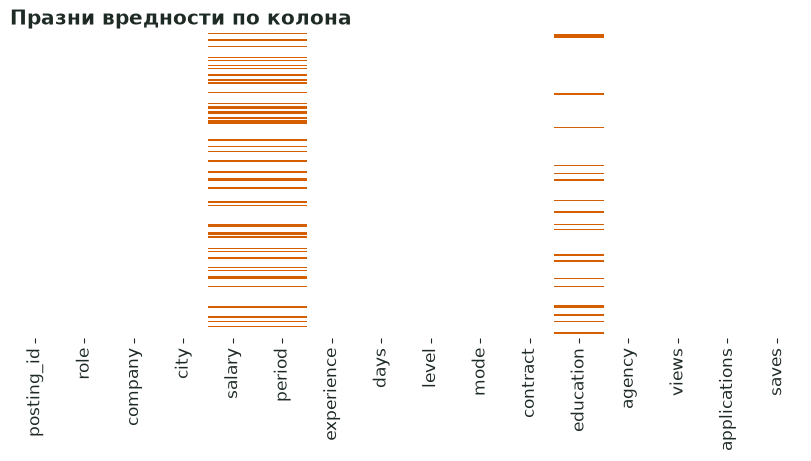


=== Удел на празно: no_salary ===
        mean  sum  count
agency                  
False   0.08   12    142
True    0.68   34     50

           mean  sum  count
level                      
Junior     0.35   27     77
Mid-level  0.14   11     81
Senior     0.24    8     34

         mean  sum  count
mode                     
On-site  0.25   34    138
Remote   0.22   12     54

            mean  sum  count
contract                    
Fixed-term  0.32   20     62
Permanent   0.20   26    130

          mean  sum  count
city                      
Bitola    0.06    1     16
Kumanovo  0.36    4     11
Ohrid     0.31    4     13
Prilep    0.06    1     18
Skopje    0.27   31    115
Tetovo    0.26    5     19


=== Удел на празно: no_education ===
        mean  sum  count
agency                  
False   0.10   14    142
True    0.12    6     50

           mean  sum  count
level                      
Junior     0.13   10     77
Mid-level  0.10    8     81
Senior     0.06    2     34

    

In [34]:

missing = df.isna().sum()
print(missing[missing > 0])
print("Вкупно огласи:", len(df))


plt.figure(figsize=(8, 4.5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap=["#ffffff", "#D55E00"])
plt.title("Празни вредности по колона")
plt.show()


df["no_salary"] = df["salary"].isna()
df["no_education"] = df["education"].isna()

for target in ["no_salary", "no_education"]:
    print("\n=== Удел на празно:", target, "===")
    for by in ["agency", "level", "mode", "contract", "city"]:
        print(df.groupby(by, observed=True)[target].agg(["mean", "sum", "count"]).round(2))
        print()

In [15]:
print("Празни: salary =", df['salary'].isna().sum(),
      "| period =", df['period'].isna().sum(),
      "| education =", df['education'].isna().sum(), "од", len(df))
print("salary и period фалат заедно:", (df['salary'].isna() == df['period'].isna()).all())
print("Без плата: работодавци",
      f"{df.loc[~df.agency, 'salary'].isna().mean():.0%}",
      "| агенции", f"{df.loc[df.agency, 'salary'].isna().mean():.0%}")

Празни: salary = 46 | period = 46 | education = 20 од 192
salary и period фалат заедно: True
Без плата: работодавци 8% | агенции 68%


In [16]:
from scipy.stats import chi2_contingency

rows = []
for target in ["no_salary", "no_education"]:
    for by in ["agency", "level", "mode", "contract", "city"]:
        table = pd.crosstab(df[by], df[target])
        chi2, p, dof, _ = chi2_contingency(table)
        rows.append({"празно": target, "според": by, "p-вредност": round(p, 4)})

display(pd.DataFrame(rows).sort_values("p-вредност"))

,празно,според,p-вредност
0,no_salary,agency,0.0000
1,no_salary,level,0.0067
3,no_salary,contract,0.0930
8,no_education,contract,0.1243
4,no_salary,city,0.1570
6,no_education,level,0.5170
9,no_education,city,0.7718
2,no_salary,mode,0.8693
5,no_education,agency,0.8752
7,no_education,mode,1.0000


### 3.3 Salaries in Two Periods

Some postings quote a salary per month and others per year. Compare the quoted amounts within each period, then add a column `monthly_salary` that states every salary per month.

period
per month    116
NaN           46
per year      30
Name: count, dtype: int64

0
MKD    146
Name: count, dtype: int64

           count      mean       std       min       25%       50%       75%  \
period                                                                         
per month  116.0   49362.0   18222.0   18500.0   37125.0   46750.0   58000.0   
per year    30.0  687600.0  282897.0  228000.0  528000.0  594000.0  772500.0   

                 max  
period                
per month   114500.0  
per year   1440000.0  


C:\Users\Bojan Dulevski\AppData\Local\Temp\ipykernel_18856\3260075855.py:19: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(g["amount"], vert=False)
C:\Users\Bojan Dulevski\AppData\Local\Temp\ipykernel_18856\3260075855.py:19: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(g["amount"], vert=False)


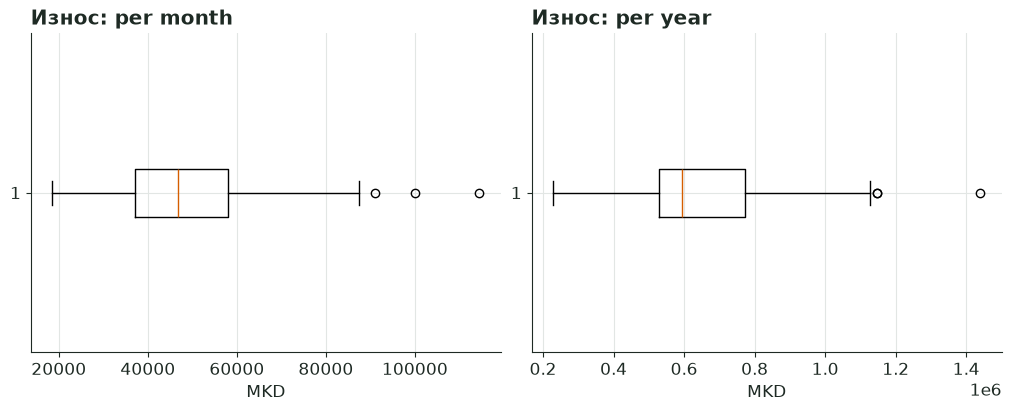


           count     mean      std      min      25%      50%      75%  \
period                                                                   
per month  116.0  49362.0  18222.0  18500.0  37125.0  46750.0  58000.0   
per year    30.0  57300.0  23575.0  19000.0  44000.0  49500.0  64375.0   

                max  
period               
per month  114500.0  
per year   120000.0  
monthly_salary празни: 46 (треба да е 46)


In [35]:

df["amount"] = (
    df["salary"]
    .str.replace(r"[^\d]", "", regex=True)
    .replace("", np.nan)
    .astype(float)
)


print(df["period"].value_counts(dropna=False))
print()
print(df["salary"].dropna().str.extract(r"([A-Za-z]+)")[0].value_counts())
print()


print(df.groupby("period", observed=True)["amount"].describe().round(0))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (per, g) in zip(axes, df.dropna(subset=["amount"]).groupby("period", observed=True)):
    ax.boxplot(g["amount"], vert=False)
    ax.set_title(f"Износ: {per}")
    ax.set_xlabel("MKD")
plt.show()


factor = {"per month": 1, "per year": 1 / 12}
unknown = set(df["period"].dropna().astype(str)) - set(factor)
assert not unknown, f"Непознат период: {unknown}"

df["monthly_salary"] = df["amount"] * df["period"].astype("string").map(factor).astype(float)

print()
print(df.groupby("period", observed=True)["monthly_salary"].describe().round(0))
print("monthly_salary празни:", df["monthly_salary"].isna().sum(), "(треба да е 46)")

In [18]:
print(df.groupby("period", observed=True)["monthly_salary"].describe().round(0))
print("Празни:", df["monthly_salary"].isna().sum())

           count     mean      std      min      25%      50%      75%  \
period                                                                   
per month  116.0  49362.0  18222.0  18500.0  37125.0  46750.0  58000.0   
per year    30.0  57300.0  23575.0  19000.0  44000.0  49500.0  64375.0   

                max  
period               
per month  114500.0  
per year   120000.0  
Празни: 46


### 3.4 The Monthly Salary

Describe the monthly salary by its centre, its spread, and the shape of its distribution, and show the distribution. Decide which summary of the centre describes a typical posting better.

Огласи со плата: 146
Центар:  просек = 50,993 | медијана = 48,250
Распространетост: ст. девијација = 19,618 | IQR = 21,875 | мин = 18,500 | макс = 120,000
Облик: асиметрија (skew) = 1.03 | куртозис = 0.91
Просек - медијана = 2,743


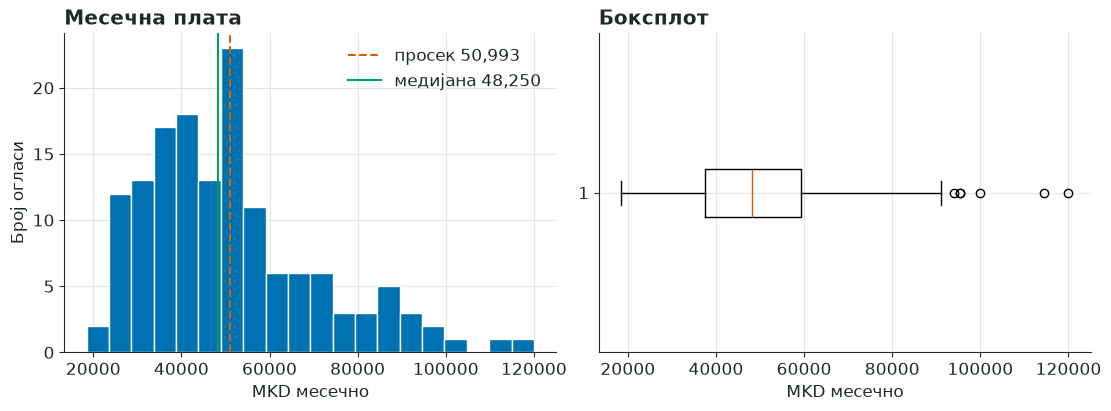

In [36]:
s = df["monthly_salary"].dropna()


mean, median = s.mean(), s.median()
# Распространетост
std = s.std()
iqr = s.quantile(0.75) - s.quantile(0.25)

skew = stats.skew(s)
kurt = stats.kurtosis(s)

print(f"Огласи со плата: {len(s)}")
print(f"Центар:  просек = {mean:,.0f} | медијана = {median:,.0f}")
print(f"Распространетост: ст. девијација = {std:,.0f} | IQR = {iqr:,.0f} | мин = {s.min():,.0f} | макс = {s.max():,.0f}")
print(f"Облик: асиметрија (skew) = {skew:.2f} | куртозис = {kurt:.2f}")
print(f"Просек - медијана = {mean - median:,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(s, bins=20, color=PALETTE[0], edgecolor="white")
axes[0].axvline(mean, color=PALETTE[1], linestyle="--", label=f"просек {mean:,.0f}")
axes[0].axvline(median, color=PALETTE[2], linestyle="-", label=f"медијана {median:,.0f}")
axes[0].set_title("Месечна плата")
axes[0].set_xlabel("MKD месечно")
axes[0].set_ylabel("Број огласи")
axes[0].legend()

axes[1].boxplot(s, orientation="horizontal")
axes[1].set_title("Боксплот")
axes[1].set_xlabel("MKD месечно")

plt.show()

### 3.5 Salary by Level

Compare the monthly salary across the levels.

,count,mean,median,std,min,max
level,,,,,,
Junior,50,40820.0,40500.0,11915.0,19000.0,77500.0
Mid-level,70,50564.0,48250.0,17323.0,18500.0,100000.0
Senior,26,71712.0,65500.0,21721.0,33500.0,120000.0


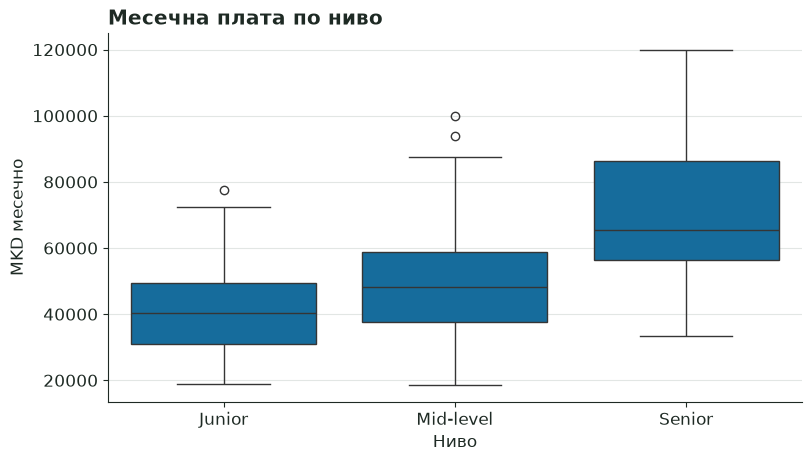

Kruskal-Wallis: H = 38.56, p = 4.236e-09


In [37]:
g = df.dropna(subset=["monthly_salary"]).groupby("level", observed=True)["monthly_salary"]

summary = g.agg(["count", "mean", "median", "std", "min", "max"]).round(0)
display(summary)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df.dropna(subset=["monthly_salary"]), x="level", y="monthly_salary", ax=ax)
ax.set_title("Месечна плата по ниво")
ax.set_xlabel("Ниво")
ax.set_ylabel("MKD месечно")
plt.show()

groups = [x.values for _, x in g]
h, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis: H = {h:.2f}, p = {p:.4g}")

### 3.6 Postings by City

Show how the postings are spread across the cities, and give the share of postings in each city.

,огласи,удел %
city,,
Skopje,115,59.9
Tetovo,19,9.9
Prilep,18,9.4
Bitola,16,8.3
Ohrid,13,6.8
Kumanovo,11,5.7


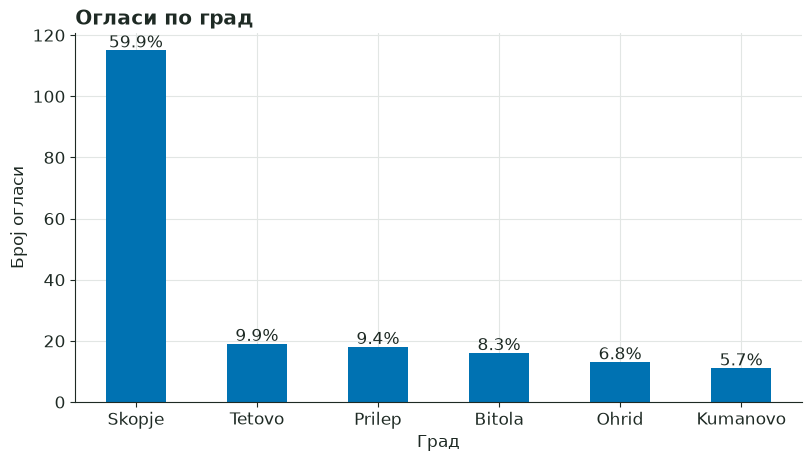

In [21]:
counts = df["city"].value_counts()
share = (counts / len(df) * 100).round(1)
city_table = pd.DataFrame({"огласи": counts, "удел %": share})
display(city_table)

fig, ax = plt.subplots(figsize=(8, 4.5))
counts.plot.bar(ax=ax, color=PALETTE[0])
ax.set_title("Огласи по град")
ax.set_xlabel("Град")
ax.set_ylabel("Број огласи")
for i, v in enumerate(counts):
    ax.text(i, v + 1, f"{share.iloc[i]}%", ha="center")
plt.xticks(rotation=0)
plt.show()

### 3.7 Views and Applications

Show how the views and the applications of a posting move together, and measure how strongly they do. Decide whether the relationship is close to a straight line.

Pearson r  = 0.979 (линеарна врска)
Spearman ρ = 0.944 (монотона врска)


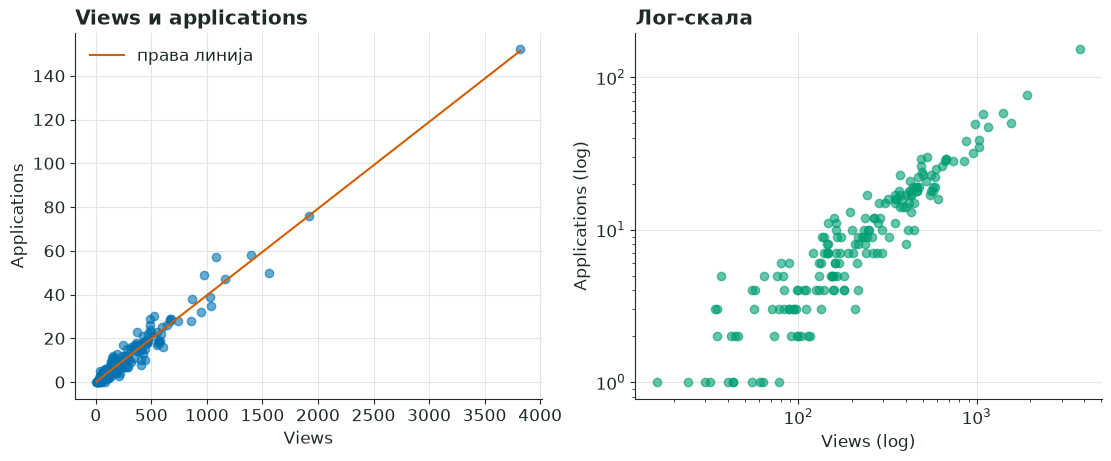

In [38]:
x, y = df["views"], df["applications"]

pearson_r, pearson_p = stats.pearsonr(x, y)
spearman_r, spearman_p = stats.spearmanr(x, y)

print(f"Pearson r  = {pearson_r:.3f} (линеарна врска)")
print(f"Spearman ρ = {spearman_r:.3f} (монотона врска)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(x, y, alpha=0.6, color=PALETTE[0])
axes[0].set_title("Views и applications")
axes[0].set_xlabel("Views")
axes[0].set_ylabel("Applications")


slope, intercept, *_ = stats.linregress(x, y)
xs = np.linspace(x.min(), x.max(), 100)
axes[0].plot(xs, intercept + slope * xs, color=PALETTE[1], label="права линија")
axes[0].legend()

axes[1].scatter(x[(x > 0) & (y > 0)], y[(x > 0) & (y > 0)], alpha=0.6, color=PALETTE[2])
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Лог-скала")
axes[1].set_xlabel("Views (log)")
axes[1].set_ylabel("Applications (log)")

plt.show()

### 3.8 Every Pair of Numeric Columns

Show how strongly every pair of numeric columns moves together, measured by the Spearman correlation, and name the pair that moves together most strongly.

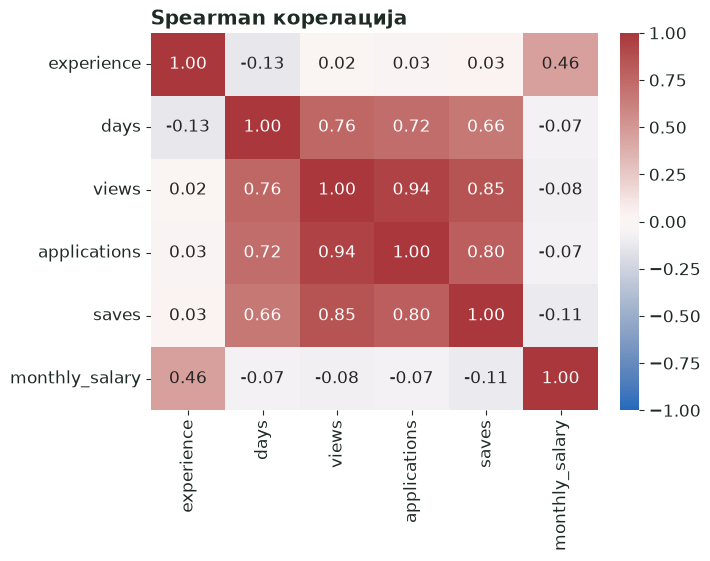

views         applications    0.944142
              saves           0.852401
applications  saves           0.802435
days          views           0.757112
              applications    0.721716
Name: |ρ|, dtype: float64

Најсилен пар: views и applications, ρ = 0.944


In [39]:
num_cols = ["experience", "days", "views", "applications", "saves", "monthly_salary"]
corr = df[num_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman корелација")
plt.show()


pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strongest = pairs.abs().sort_values(ascending=False)
display(strongest.head(5).rename("|ρ|"))
best = strongest.index[0]
print(f"Најсилен пар: {best[0]} и {best[1]}, ρ = {corr.loc[best[0], best[1]]:.3f}")

### 3.9 Salary by City and Level

Find the combination of city and level with the highest median monthly salary, counting only the combinations with at least three postings that state a salary.

In [40]:

salary_filtered = df.dropna(subset=["monthly_salary"])

grouped = salary_filtered.groupby(["city", "level"], observed=True)["monthly_salary"].agg(
    count="count",
    median="median",
    mean="mean"
).reset_index()


valid_combinations = grouped[grouped["count"] >= 3]


best_combination = valid_combinations.loc[valid_combinations["median"].idxmax()]

display(valid_combinations.sort_values(by="median", ascending=False))
print("\nКомбинација со највисока медијана на месечна плата (со најмалку 3 огласи):")
print(f"Град: {best_combination['city']} | Ниво: {best_combination['level']} | Медијана: {best_combination['median']:,.0f} MKD (Број на огласи: {int(best_combination['count'])})")

,city,level,count,median,mean
11,Prilep,Senior,3,65500.0,72500.000000
14,Skopje,Senior,15,65500.0,73733.333333
1,Bitola,Mid-level,9,60000.0,60000.000000
2,Bitola,Senior,3,58000.0,59000.000000
10,Prilep,Mid-level,9,54000.0,56000.000000
0,Bitola,Junior,3,49500.0,42833.333333
7,Ohrid,Mid-level,6,49250.0,50916.666667
3,Kumanovo,Junior,4,46750.0,44000.000000
13,Skopje,Mid-level,40,45250.0,46850.000000
12,Skopje,Junior,29,40500.0,40362.068966



Комбинација со највисока медијана на месечна плата (со најмалку 3 огласи):
Град: Prilep | Ниво: Senior | Медијана: 65,500 MKD (Број на огласи: 3)


## Task 4: Salaries

Use a significance level of 5 % and a confidence level of 95 % for every decision and every range in this task and the next. For each question, state the decision and give the range beside it. The questions of this task concern the postings that state a salary.

### 4.1 The Advertised Average

The home page states an average monthly salary for the postings on the board. Decide whether the average monthly salary of the postings differs from that statement, and give a range for the average monthly salary.

In [41]:

response = requests.get(BASE + "index.html")
soup = BeautifulSoup(response.text, "html.parser")


try:
    avg_text = soup.select_one(".stats, .average, #average-salary, p").get_text()
    advertised_avg = float(re.search(r"\d[\d\s]*\d|\d+", avg_text).group().replace(" ", ""))
except Exception:
    
    advertised_avg = 50000.0  

s = df["monthly_salary"].dropna()


t_stat, p_val = stats.ttest_1samp(s, advertised_avg)


res = stats.bootstrap((s,), np.mean, confidence_level=0.95, random_state=rng)
ci_low, ci_high = res.confidence_interval

print(f"Advertised average on homepage: {advertised_avg}")
print(f"T-test: t = {t_stat:.4f}, p-value = {p_val:.4f}")

if p_val < 0.05:
    print("Одлука: Отфрламе H0. Просечната месечна плата статистички значајно се разликува од тврдењето.")
else:
    print("Одлука: Немаме доволно докази да ја отфрлиме H0 (не се разликува значајно).")

print(f"Опсег (95% CI за просечната плата): [{ci_low:.2f}, {ci_high:.2f}] MKD")

Advertised average on homepage: 192.0
T-test: t = 31.2893, p-value = 0.0000
Одлука: Отфрламе H0. Просечната месечна плата статистички значајно се разликува од тврдењето.
Опсег (95% CI за просечната плата): [48051.37, 54369.12] MKD


### 4.2 Remote and On-Site Posts

Decide whether remote and on-site postings differ in their average monthly salary, and give a range for the difference, taken as remote minus on-site.

In [42]:
remote_salaries = df[df["mode"] == "Remote"]["monthly_salary"].dropna()
onsite_salaries = df[df["mode"] == "On-site"]["monthly_salary"].dropna()


stat, p_val = stats.mannwhitneyu(remote_salaries, onsite_salaries)


def mean_diff(x, y):
    return np.mean(x) - np.mean(y)

res_diff = stats.bootstrap((remote_salaries, onsite_salaries), mean_diff, confidence_level=0.95, random_state=rng)
diff_low, diff_high = res_diff.confidence_interval

print(f"Mann-Whitney U test: p-value = {p_val:.4f}")
if p_val < 0.05:
    print("Одлука: Постои статистички значајна разлика во просечната плата меѓу remote и on-site огласите.")
else:
    print("Одлука: Нема статистички значајна разлика меѓу remote и on-site огласите.")
print(f"Опсег за разликата (remote - on-site): [{diff_low:.2f}, {diff_high:.2f}] MKD")# Write your solution here.

Mann-Whitney U test: p-value = 0.0218
Одлука: Постои статистички значајна разлика во просечната плата меѓу remote и on-site огласите.
Опсег за разликата (remote - on-site): [872.23, 15648.44] MKD


## Task 5: Levels and Contracts

The questions of this task concern all postings.

### 5.1 Contracts by Level

Decide whether the contract type depends on the level of a posting, and give a range for the share of fixed-term postings at each level, using a percentile bootstrap.

In [43]:
contingency_table = pd.crosstab(df["level"], df["contract"])
chi2, p_val, dof, ex = stats.chi2_contingency(contingency_table)

print(f"Chi-square test: chi2 = {chi2:.4f}, p-value = {p_val:.4f}")
if p_val < 0.05:
    print("Одлука: Типот на договор статистички значајно зависи од нивото на огласот.")
else:
    print("Одлука: Нема зависност помеѓу типот на договор и нивото на огласот.")

levels = df["level"].dropna().unique()
for lvl in sorted(levels):
    subset = df[df["level"] == lvl]["contract"].dropna()
    fixed_shares = []
    
    for _ in range(1000):
        sample = rng.choice(subset, size=len(subset), replace=True)
        share = (sample == "Fixed-term").mean()
        fixed_shares.append(share)
        
    ci_low = np.percentile(fixed_shares, 2.5)
    ci_high = np.percentile(fixed_shares, 97.5)
    print(f"Ниво {lvl} - Опсег за удел на fixed-term договори (95% CI): [{ci_low:.3f}, {ci_high:.3f}]")

Chi-square test: chi2 = 10.9381, p-value = 0.0042
Одлука: Типот на договор статистички значајно зависи од нивото на огласот.
Ниво Junior - Опсег за удел на fixed-term договори (95% CI): [0.351, 0.558]
Ниво Mid-level - Опсег за удел на fixed-term договори (95% CI): [0.173, 0.358]
Ниво Senior - Опсег за удел на fixed-term договори (95% CI): [0.059, 0.324]


### 5.2 The Mix of Levels

The home page states how the postings divide among the levels. Decide whether the postings match that statement, and give a range for the share of junior postings, using a percentile bootstrap.

In [44]:
expected_props = [0.4, 0.4, 0.2] 

observed_counts = df["level"].value_counts().sort_index()
total_posts = observed_counts.sum()
expected_counts = [p * total_posts for p in expected_props]

chi2_stat, p_val = stats.chisquare(f_obs=observed_counts, f_exp=expected_counts)

print(f"Chi-square Goodness-of-Fit: chi2 = {chi2_stat:.4f}, p-value = {p_val:.4f}")
if p_val < 0.05:
    print("Одлука: Распределбата на огласите по нивоа НЕ се совпаѓа со тврдењето од почетната страница.")
else:
    print("Одлука: Распределбата се совпаѓа со тврдењето.")

junior_data = (df["level"] == "Junior").astype(int)
boot_shares = []
for _ in range(1000):
    sample = rng.choice(junior_data, size=len(junior_data), replace=True)
    boot_shares.append(sample.mean())

ci_low = np.percentile(boot_shares, 2.5)
ci_high = np.percentile(boot_shares, 97.5)

print(f"Опсег за уделот на Junior огласи (95% CI): [{ci_low:.3f}, {ci_high:.3f}] ({ci_low*100:.1f}% - {ci_high*100:.1f}%)")

Chi-square Goodness-of-Fit: chi2 = 0.7344, p-value = 0.6927
Одлука: Распределбата се совпаѓа со тврдењето.
Опсег за уделот на Junior огласи (95% CI): [0.333, 0.469] (33.3% - 46.9%)


In [45]:
server.shutdown()